# Tiny AlphaZero on a Real 3×3 Go Board

**Goal:** Run a complete game, inspect one MCTS search, create training labels, compute real gradients, and observe learning from random weights.

Rules retained: alternating Black/White moves, liberties, captures, no suicide, positional superko, pass, end after two consecutive passes, and Chinese-style area scoring. White gets **0.5 komi** to avoid ties. This is a teaching-sized board, not standard 19×19 Go.

**Notation for one position:**

| Symbol | Concrete meaning |
|:--|:--|
| `s` | The 3×3 board, whose turn it is, pass count, and history |
| `θ` | The 1,035 trainable numbers inside our small neural network |
| `p` | Network's probability for each of 9 points plus `PASS` |
| `v` | Network's estimated final result for the player to move |
| `N(a)` | How many MCTS simulations chose root action `a` |
| `Q(a)` | Mean backed-up outcome for that action |
| `π` | The normalized root visit counts `N / sum(N)` |
| `z` | Actual final outcome, `+1` win or `-1` loss, from that player's perspective |

The rules engine is separate from the neural network: **legal moves are computed exactly**, not learned.

In [2]:
from dataclasses import dataclass
import numpy as np
import torch
from torch import nn

BOARD_SIZE = 3
BOARD_CELLS = BOARD_SIZE ** 2
PASS = BOARD_CELLS
KOMI = 0.5
ACTIONS = BOARD_CELLS + 1

@dataclass(frozen=True)
class State:
    board: tuple
    turn: int
    passes: int
    history: frozenset


def initial_state():
    board = (0,) * BOARD_CELLS
    return State(board, 1, 0, frozenset([board]))


def neighbors(pos):
    r, c = divmod(pos, BOARD_SIZE)
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        rr, cc = r + dr, c + dc
        if 0 <= rr < BOARD_SIZE and 0 <= cc < BOARD_SIZE:
            yield rr * BOARD_SIZE + cc


def group_and_liberties(board, start):
    color = board[start]
    group, liberties, todo = {start}, set(), [start]
    while todo:
        pos = todo.pop()
        for adj in neighbors(pos):
            if board[adj] == 0:
                liberties.add(adj)
            elif board[adj] == color and adj not in group:
                group.add(adj)
                todo.append(adj)
    return group, liberties


def play(state, action):
    if state.passes == 2:
        return None
        
    if action == PASS:
        return State(state.board, -state.turn, state.passes + 1, state.history)
        
    if not (0 <= action < BOARD_CELLS) or state.board[action] != 0:
        return None
        
    board = list(state.board)
    board[action] = state.turn
    
    for adj in neighbors(action):
        if board[adj] == -state.turn:
            group, liberties = group_and_liberties(board, adj)
            if len(liberties) == 0:
                for pos in group:
                    board[pos] = 0
                    
    _, liberties = group_and_liberties(board, action)
    
    if len(liberties) == 0:
        return None
        
    b = tuple(board)
    if b in state.history:
        return None
        
    return State(b, -state.turn, 0, state.history | {b})
    

def legal_moves(state):
    return [a for a in range(ACTIONS) if play(state, a) is not None]


def area_scores(board):
    black = sum(v == 1 for v in board)
    white = sum(v == -1 for v in board) + KOMI
    visited = set()
    for i in range(BOARD_CELLS):
        if board[i] or i in visited:
            continue
        region, boundary, todo = {i}, set(), [i]
        visited.add(i)
        while todo:
            pos = todo.pop()
            for adj in neighbors(pos):
                if board[adj] == 0 and adj not in visited:
                    visited.add(adj)
                    region.add(adj)
                    todo.append(adj)
                elif board[adj] != 0:
                    boundary.add(board[adj])
        if boundary == {1}:
            black += len(region)
        elif boundary == {-1}:
            white += len(region)
    return black, white


def final_value(state):
    b, w = area_scores(state.board)
    winner = 1 if b > w else -1 if w > b else 0
    return float(winner * state.turn)


def board_text(board):
    chars = {0: '.', 1: 'X', -1: 'O'}
    return '\n'.join(' '.join(chars[board[r * BOARD_SIZE + c]] for c in range(BOARD_SIZE)) for r in range(BOARD_SIZE))


def action_text(a):
    return 'PASS' if a == PASS else f'{chr(65 + a // BOARD_SIZE)}{1 + (a % BOARD_SIZE)}'



In [3]:
# Confirm that a real capture removes the surrounded white stone.
setup = (0, 1, 0,
         1,-1, 0,
         0, 1, 0)
puzzle = State(setup, 1, 0, frozenset([setup]))
print('Before black B3:')
print(board_text(puzzle.board))
print('\nAfter black B3:')
print(board_text(play(puzzle, 5).board))
print('Legal actions from the empty board:', [action_text(a) for a in legal_moves(initial_state())])

Before black B3:
. X .
X O .
. X .

After black B3:
. X .
X . X
. X .
Legal actions from the empty board: ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3', 'PASS']


## 1. The randomly initialized network

The input is a **20-number vector**: nine `my stone` flags, nine `opponent stone` flags, whether the player to move is Black, and the consecutive-pass count. The network has a 32-unit hidden layer, producing **10 action logits** and **one raw value**. Softmax (after masking illegal actions) makes `p`; `tanh` makes `v`.

`θ` is the collection of weight matrices and biases. We print representative slices rather than listing all 1,035 numbers.

In [4]:
def encode(state):
    b = np.asarray(state.board)
    
    return np.r_[
        b == state.turn, 
        b == -state.turn, 
        [int(state.turn == 1), state.passes / 2]
    ].astype(np.float32)


class TinyGoNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(20, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, ACTIONS + 1)

    def forward(self, x):
        hidden = self.relu(self.fc1(x))
        out = self.fc2(hidden)
        return out[..., :ACTIONS], out[..., ACTIONS]


def network_prediction(net, state):
    with torch.no_grad():
        logits, raw_v = net(torch.from_numpy(encode(state)))        
        masked_logits = logits.detach().numpy().copy()
        
        mask = np.ones(ACTIONS, dtype=bool)
        legal = legal_moves(state)
        mask[legal] = False
        masked_logits[mask] = -1e9
        
        p = torch.softmax(torch.from_numpy(masked_logits), dim=0).numpy()
        v = float(torch.tanh(raw_v))
        
    return p, v


# Fix the seed so all random initial weights and moves are reproducible.
torch.set_num_threads(1)
torch.manual_seed(3)
rng = np.random.default_rng(3)
net = TinyGoNet()
print('Input vector for empty board:', encode(initial_state()).astype(int).tolist())
print('Weight matrix shapes:', tuple(net.fc1.weight.shape), tuple(net.fc2.weight.shape))
print('Total trainable θ values:', sum(t.numel() for t in net.parameters()))
print('A real slice of θ:', net.fc1.weight[0, :5].detach().numpy().round(4))
p, v = network_prediction(net, initial_state())
print('Initial p =', {action_text(a): round(float(p[a]), 3) for a in range(ACTIONS)})
print('Initial v =', round(v, 4))

Input vector for empty board: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
Weight matrix shapes: (32, 20) (11, 32)
Total trainable θ values: 1035
A real slice of θ: [-0.2217 -0.1764 -0.0958 -0.2116 -0.0127]
Initial p = {'A1': 0.084, 'A2': 0.118, 'A3': 0.085, 'B1': 0.101, 'B2': 0.085, 'B3': 0.085, 'C1': 0.087, 'C2': 0.127, 'C3': 0.119, 'PASS': 0.11}
Initial v = 0.0155


## 2. MCTS

TreeNode: a game state snapshot

Edge: next step at that snapshot

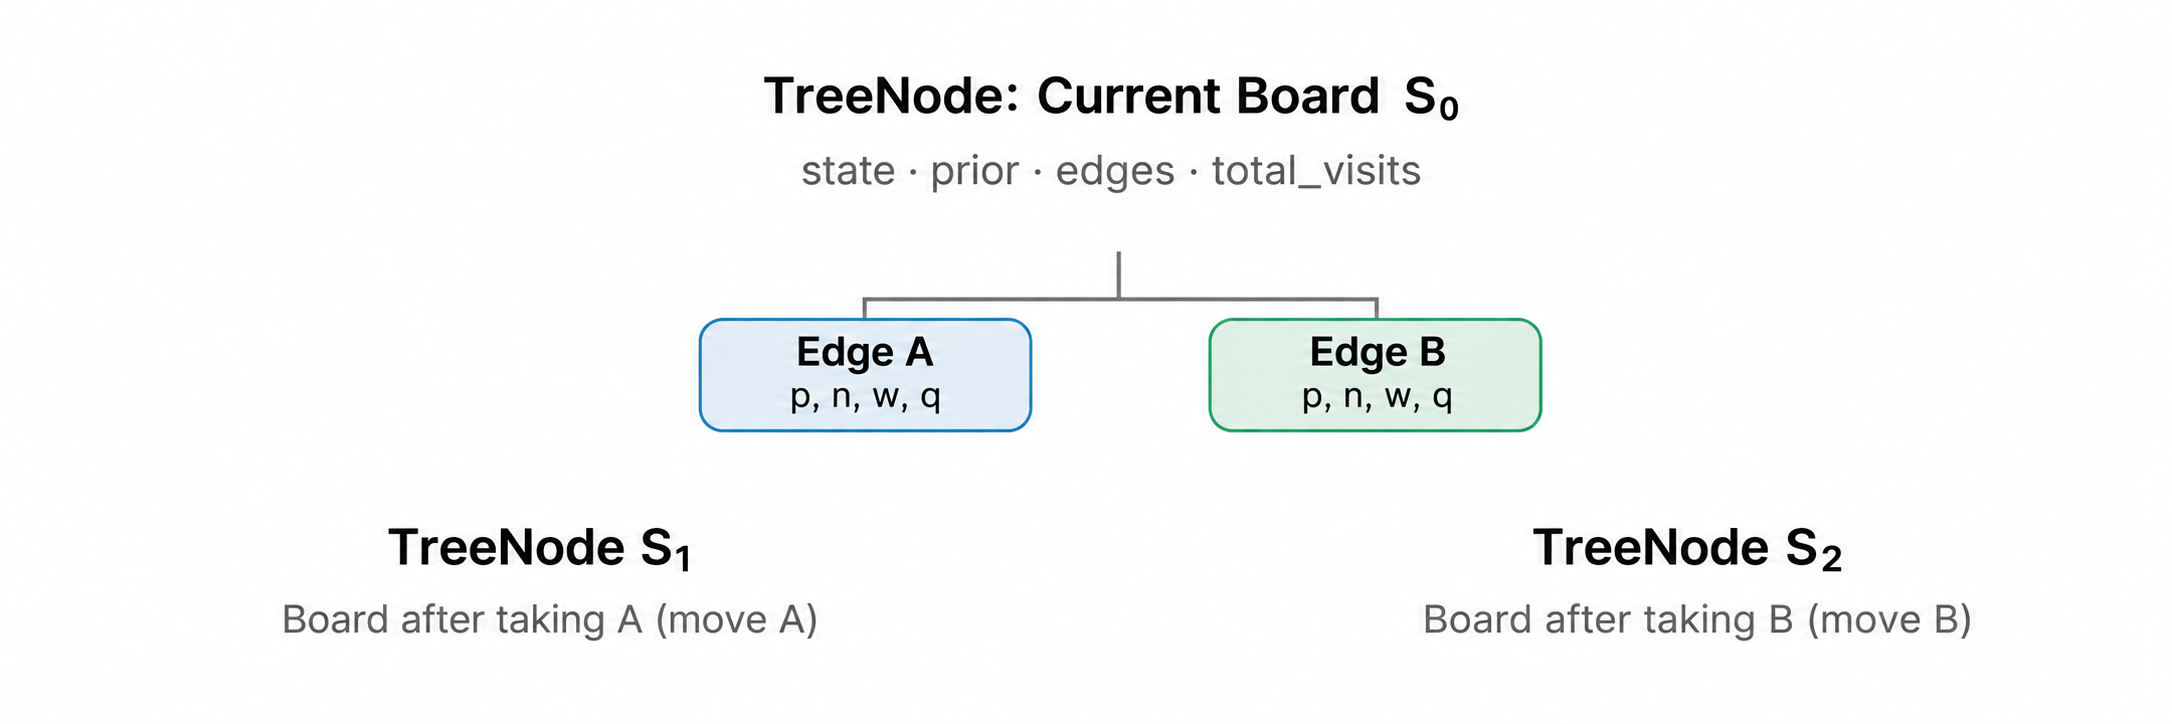

In [6]:
class TreeNode:
    def __init__(self, state, prior):
        self.state = state
        self.prior = np.array(prior, dtype=np.float64) # NN policy prediction
        self.edges = {}
        self.total_visits = 0


class Edge:
    def __init__(self, prior):
        self.p = float(prior) # NN's probability
        self.n = 0 # visit count
        self.w = 0.0 # total value
        self.child = None

    @property
    def q(self):
        # Use Mean value for Q value
        # don't know P to calculate Expected value. it's like a MC estimate
        return self.w / self.n if self.n else 0.0


def search(net, state, rng, simulations=32, cpuct=1.8, noise=True, trace=False):
    # root nodes don't need value
    base_prior, _ = network_prediction(net, state)
    root_prior = base_prior.copy()

    legal = legal_moves(state)
    
    if noise:
        # add noise to only to root explore more (Read PUCT)
        d = rng.dirichlet([0.30] * len(legal))
        root_prior[legal] = 0.75 * root_prior[legal] + 0.25 * d
        
    root = TreeNode(state, root_prior)
    root.edges = {a: Edge(root_prior[a]) for a in legal}
    traces = []
    
    for sim in range(simulations):
        node = root
        path = []
        
        while True:
            scale = np.sqrt(1 + node.total_visits)
            action = max(node.edges, 
                         key=lambda a: node.edges[a].q + cpuct * node.edges[a].p * scale / (1 + node.edges[a].n))
            
            edge = node.edges[action]
            
            path.append((node, action, edge))
            next_state = play(node.state, action)
            
            if next_state.passes == 2:
                v = final_value(next_state)
                leaf = 'terminal'
                break
                
            if edge.child is None:
                # edge and v here ALWAYS changes perspective
                p, v = network_prediction(net, next_state)
                child = TreeNode(next_state, p)
                child.edges = {a: Edge(p[a]) for a in legal_moves(next_state)}
                edge.child = child
                
                leaf = 'network'
                break
                
            node = edge.child
            
        for ancestor, a, edge in reversed(path):
            # Every level, translate edge to the perspective of THIS LEVEL PLAYER!
            v = -v
            edge.n += 1
            edge.w += v
            ancestor.total_visits += 1
            
        if trace and sim < 4:
            traces.append(([action_text(a) for _, a, _ in path], leaf, float(v)))
            
    counts = np.zeros(ACTIONS, dtype=np.float32)

    # Calculate policy to learn using MCST search count 
    for a, edge in root.edges.items():
        counts[a] = edge.n
    pi = counts / counts.sum()
    
    return pi, root, base_prior, traces



In [8]:
def self_play(net, rng, simulations=32, collect_logs=False, tau=1.0):
    state = initial_state()
    records, moves = [], []
    first_detail = None
    
    while state.passes < 2:
        pi, root, prior, traces = search(net, state, rng, simulations, noise=True, trace=(first_detail is None))

        # tau is temperature, tau = 1.0 means using original visit count.
        if tau <= 0:
            action = int(np.argmax(pi))
        else:
            weights = pi ** (1 / tau)
            weights = weights / weights.sum()
            action = int(rng.choice(ACTIONS, p=weights))
            
        if first_detail is None:
            first_detail = (state, prior, pi, root, traces)
            
        records.append((encode(state), pi.copy(), state.turn, state, action))
        moves.append((state.turn, action, state.board, play(state, action).board))
        
        state = play(state, action)
        
    black, white = area_scores(state.board)
    winner = 1 if black > white else -1 if white > black else 0
    
    examples = [
        (state, pi, float(winner * turn)) 
        for _, pi, turn, state, _ in records
       ]
    
    if collect_logs:
        return examples, moves, (black, white, winner), first_detail
        
    return examples


def compute_loss(net, examples):
    # shape:(num of example, state encoded)
    x = torch.from_numpy(
        np.stack([encode(i[0]) for i in examples])
    )

    # illegal moves won't contribute to loss. We already have a way to remove illegal moves
    # don't need to train nn to avoid illegal moves. In other words, the value of learning this is LOW.
    mask = torch.tensor(
        [[a in legal_moves(i[0]) for a in range(ACTIONS)] 
         for i in examples], 
        dtype=torch.bool
    )

    # target policy to learn from
    pi = torch.from_numpy(
        np.stack([i[1] for i in examples])
    )

    # target result to learn
    z = torch.tensor(
        [i[2] for i in examples], 
        dtype=torch.float32
    )
    
    logits, raw_v = net(x)
    value = torch.tanh(raw_v)
    
    masked_logits = logits.masked_fill(~mask, -1e9)
    
    policy_loss = -(
        pi * torch.log_softmax(masked_logits, dim=-1)
    ).sum(-1).mean()
    
    value_loss = ((value - z)**2).mean()
    
    return policy_loss + value_loss, policy_loss, value_loss

# One full self-play game; do not update θ during the game.
import copy
initial_net = copy.deepcopy(net)

examples, moves, result, first = self_play(net, rng, simulations=32, collect_logs=True)

print('ONE COMPLETE GAME')

for step, (turn, action, before, after) in enumerate(moves, 1):
    print(f'\nMove {step}: {"Black" if turn == 1 else "White"} -> {action_text(action)}')
    print(board_text(after))
    
print(f'\nArea score: Black={result[0]:g}, White={result[1]:g}')
print('Winner:', 'Black' if result[2] == 1 else 'White')

root_state, prior, pi, root, traces = first
print('\nFIRST POSITION: 32 MCTS SIMULATIONS')
print(f'{"Action":<8} {"p prior":>8} {"Visits N":>9} {"Q":>8} {"pi":>8}')

for a, edge in root.edges.items():
    print(f'{action_text(a):<8} {prior[a]:>8.3f} {edge.n:>9} {edge.q:>8.3f} {pi[a]:>8.3f}')
    
print('First four simulations (selected path, leaf type, backed-up root value):')

for path, leaf_type, value in traces:
    print(' ', ' -> '.join(path), leaf_type, f'{value:+.3f}')
    
print('\nActual first move:', action_text(moves[0][1]))
print('Training label for first move: pi=', np.round(examples[0][1], 3), 'z=', examples[0][2])
print('All training z labels:', [int(e[2]) for e in examples])

ONE COMPLETE GAME

Move 1: Black -> A2
. X .
. . .
. . .

Move 2: White -> B1
. X .
O . .
. . .

Move 3: Black -> C2
. X .
O . .
. X .

Move 4: White -> PASS
. X .
O . .
. X .

Move 5: Black -> PASS
. X .
O . .
. X .

Area score: Black=2, White=1.5
Winner: Black

FIRST POSITION: 32 MCTS SIMULATIONS
Action    p prior  Visits N        Q       pi
A1          0.084         2   -0.044    0.062
A2          0.118         4   -0.042    0.125
A3          0.085         1   -0.176    0.031
B1          0.101         2   -0.040    0.062
B2          0.085         2   -0.058    0.062
B3          0.085         2   -0.053    0.062
C1          0.087         9   -0.053    0.281
C2          0.127         3   -0.076    0.094
C3          0.119         4    0.028    0.125
PASS        0.110         3   -0.053    0.094
First four simulations (selected path, leaf type, backed-up root value):
  C1 network -0.139
  A2 network -0.029
  PASS network -0.105
  C2 network -0.058

Actual first move: A2
Training label f

## 3. Does repeated self-play improve play?

Repeat **self-play → MCTS labels → final score labels → Adam update** 200 times. To evaluate the *learned network* rather than the search, play **greedy network policy without MCTS** against a uniformly random legal-move opponent, in both colors. This simple opponent is a sanity check, not a proof of optimal Go play or guaranteed convergence. Evaluation seeds are fixed.

In [10]:
def match(net, rng, net_color, games=100):
    won = 0
    for _ in range(games):
        s=initial_state()
        
        while s.passes<2:
            legal = legal_moves(s)
            if s.turn==net_color:
                probs,_=network_prediction(net,s)
                a=int(max(legal,key=lambda a:probs[a]))
            else:
                a=int(rng.choice(legal))
            s=play(s,a)
            
        b,w=area_scores(s.board)
        winner=1 if b>w else -1 if w>b else 0
        won += 1 if winner==net_color else 0.5 if winner==0 else 0
        
    return won/games

optimizer = torch.optim.Adam(net.parameters(), lr=0.008)
print('Before training: win rate vs random')
print('Black:', f'{match(initial_net, np.random.default_rng(2027), 1):.1%}',
      'White:', f'{match(initial_net, np.random.default_rng(2027), -1):.1%}')
print('\nGame | last loss | initial-board P(center) | win rate as Black | as White')

for game in range(1, 201):
    samples = self_play(net, rng, simulations=24)
    optimizer.zero_grad()
    total, pol, val = compute_loss(net, samples)
    
    total.backward()
    torch.nn.utils.clip_grad_norm_(net.parameters(), 5)
    optimizer.step()
    
    if game in (1, 30, 100, 200):
        center = float(network_prediction(net, initial_state())[0][4])
        black = match(net, np.random.default_rng(2027), 1)
        white = match(net, np.random.default_rng(2027), -1)
        print(f'{game:>4} | {total.item():>9.3f} | {center:>23.1%} | {black:>17.1%} | {white:>8.1%}')

Before training: win rate vs random
Black: 24.0% White: 26.0%

Game | last loss | initial-board P(center) | win rate as Black | as White
   1 |     2.572 |                    8.6% |             32.0% |    31.0%
  30 |     2.610 |                   13.1% |             21.0% |    31.0%
 100 |     3.312 |                   61.6% |             93.0% |    97.0%
 200 |     0.973 |                   96.8% |            100.0% |    99.0%
